# Exercises for the report — notebook

Companion notebook for [Exercises for the report](index.md).

- **Exercise 1, The Basel problem**: a runnable Python/NumPy implementation (partial sums in single precision, direct and reverse order, convergence study, error plot).
- **Exercise 2, Parallel Hello, World!**: reference material (Python threading demo, C OpenMP and hybrid MPI + OpenMP sources, `mpi4py` sketch, Slurm batch templates).

Environment: Python with NumPy and Matplotlib (kernel `hpc4ai`). All floating-point types are stated explicitly so the precision is unambiguous.

## Exercise 1 — The Basel problem

We verify numerically that the partial sum

$$S(N) = \sum_{n=1}^{N} \frac{1}{n^2}$$

tends to $\zeta(2) = \pi^2/6 = 1.6449340668482264\dots$, and we study how the **order of summation** changes a single-precision (`float32`) result.

Two error sources:

- **truncation**: dropping the tail, $\pi^2/6 - S(N) \approx 1/N$;
- **rounding**: adding a tiny term to a large running sum loses bits once the term is below $\varepsilon \cdot S$, with $\varepsilon = 2^{-23} \approx 1.19\times10^{-7}$ for `float32`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

EXACT = np.pi**2 / 6          # reference value, double precision
EPS32 = np.finfo(np.float32).eps

print(f"pi^2/6            = {EXACT:.15f}")
print(f"float32 epsilon   = {EPS32:.3e}  (2^-23)")
print(f"float32 digits    ~ {-np.log10(EPS32):.1f}")

pi^2/6            = 1.644934066848226
float32 epsilon   = 1.192e-07  (2^-23)
float32 digits    ~ 6.9


### Partial sum in single precision

The terms are generated in `float64` (so the index `n` is exact up to large $N$) and **cast to `float32`**; the accumulation itself is `float32`. To emulate a naive sequential sum at C-like speed, each chunk is accumulated with `np.cumsum` (sequential, not pairwise) and the chunk result is added to the running total. Chunking keeps memory bounded, so $N = 10^9$ would not allocate 4 GB at once.

In [2]:
CHUNK = 2**20  # 1 048 576 terms per chunk, ~4 MB as float32


def partial_sum(N, order="direct", chunk=CHUNK):
    """Single-precision partial sum of 1/n^2 for n = 1..N.

    order="direct"  -> sum n = 1, 2, 3, ... (large terms first)
    order="reverse" -> sum n = N, N-1, ..., 1 (small terms first)
    """
    total = np.float32(0.0)
    if order == "direct":
        for start in range(0, N, chunk):
            stop = min(start + chunk, N)
            n = np.arange(start + 1, stop + 1, dtype=np.float64)
            terms = (1.0 / n**2).astype(np.float32)
            total = np.float32(total + np.cumsum(terms, dtype=np.float32)[-1])
    elif order == "reverse":
        stop = N
        while stop > 0:
            start = max(0, stop - chunk)
            n = np.arange(stop, start, -1, dtype=np.float64)
            terms = (1.0 / n**2).astype(np.float32)
            total = np.float32(total + np.cumsum(terms, dtype=np.float32)[-1])
            stop = start
    else:
        raise ValueError("order must be 'direct' or 'reverse'")
    return float(total)


def report(N):
    """One machine-readable record per summation order."""
    for order in ("direct", "reverse"):
        s = partial_sum(N, order)
        err = abs(s - EXACT)  # error in double precision
        print(f"N={N:<12d} order={order:<7s} sum={s:.9f} abs_error={err:.6e}")


report(10**6)

N=1000000      order=direct  sum=1.644725323 abs_error=2.087441e-04
N=1000000      order=reverse sum=1.644932985 abs_error=1.081542e-06


### Convergence study

Sample $N$ on a **log-spaced grid** (the error scales as a power of $N$) and record the absolute error for both orders.

In [3]:
Ns = np.unique(np.round(np.logspace(2, 8, 25)).astype(np.int64))

record = {"direct": [], "reverse": []}
for N in Ns:
    for order in ("direct", "reverse"):
        record[order].append(abs(partial_sum(int(N), order) - EXACT))

print(f"{'N':>12s} {'direct err':>14s} {'reverse err':>14s}")
for i, N in enumerate(Ns):
    print(f"{N:>12d} {record['direct'][i]:14.3e} {record['reverse'][i]:14.3e}")

           N     direct err    reverse err
         100      9.950e-03      9.950e-03
         178      5.602e-03      5.602e-03
         316      3.159e-03      3.160e-03
         562      1.778e-03      1.778e-03
        1000      9.992e-04      9.996e-04
        1778      5.612e-04      5.623e-04
        3162      3.201e-04      3.163e-04
        5623      2.087e-04      1.779e-04
       10000      2.087e-04      1.000e-04
       17783      2.087e-04      5.628e-05
       31623      2.087e-04      3.160e-05
       56234      2.087e-04      1.777e-05
      100000      2.087e-04      1.002e-05
      177828      2.087e-04      5.611e-06
      316228      2.087e-04      3.227e-06
      562341      2.087e-04      1.797e-06
     1000000      2.087e-04      1.082e-06
     1778279      2.084e-04      4.855e-07
     3162278      2.081e-04      3.663e-07
     5623413      2.080e-04      1.279e-07
    10000000      2.080e-04      1.279e-07
    17782794      2.080e-04      1.279e-07
    3162277

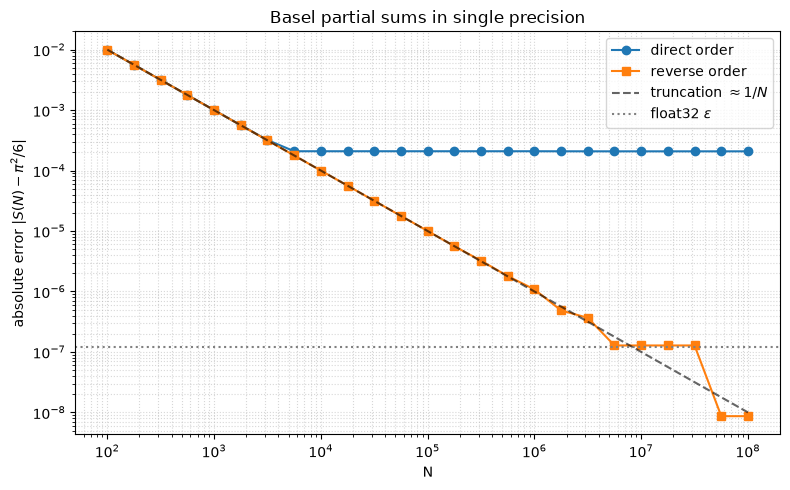

In [4]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.loglog(Ns, record["direct"], "o-", label="direct order")
ax.loglog(Ns, record["reverse"], "s-", label="reverse order")
ax.loglog(Ns, 1.0 / Ns, "k--", alpha=0.6, label=r"truncation $\approx 1/N$")
ax.axhline(EPS32, color="0.5", linestyle=":", label=r"float32 $\varepsilon$")

ax.set_xlabel("N")
ax.set_ylabel(r"absolute error $|S(N) - \pi^2/6|$")
ax.set_title("Basel partial sums in single precision")
ax.grid(True, which="both", linestyle=":", alpha=0.5)
ax.legend()
plt.tight_layout()
plt.show()

### Reading the plot

- For small $N$ both orders coincide: **truncation** dominates and the error follows $1/N$.
- The **direct** curve flattens early (around $N \approx 5\times10^3$): once $1/n^2 < \varepsilon\,S \approx 2\times10^{-7}$, i.e. $n \gtrsim 2200$, new terms no longer change the running sum. Adding more terms cannot improve it.
- The **reverse** curve keeps improving because the smallest terms are added while the running sum is still small, so their relative precision is preserved. It approaches the single-precision floor $\sim \varepsilon$ (and can even dip below, since the absolute error is small near the exact value).
- The exercise answer: direct and reverse sums **disagree** for large $N$; reverse is closer to $\pi^2/6$.

### Reproducing in C and C++

Same algorithm, scalar loop, with an explicit order and an error computed in `double`:

```c
/* basel.c: compile with gcc -O2 -Wall -Wextra -o basel basel.c -lm */
#include <stdio.h>
#include <stdlib.h>
#include <math.h>

int main(int argc, char **argv)
{
    long N = (argc > 1) ? atol(argv[1]) : 1000000;
    int reverse = (argc > 2);           /* any 2nd arg -> reverse order */
    float sum = 0.0f;

    if (reverse) {
        for (long n = N; n >= 1; --n) sum += 1.0f / ((float)n * (float)n);
    } else {
        for (long n = 1; n <= N; ++n) sum += 1.0f / ((float)n * (float)n);
    }

    double exact = M_PI * M_PI / 6.0;
    printf("N=%ld order=%s sum=%.9f abs_error=%.6e\n",
           N, reverse ? "reverse" : "direct", (double)sum, fabs((double)sum - exact));
    return 0;
}
```

State the compiler and options in the report. Avoid `-ffast-math` / `-Ofast`: they let the compiler reassociate the sum and defeat the point of the comparison. With such options the scalar loop may also be auto-vectorized, which changes both speed and accuracy.

## Exercise 2 — Parallel Hello, World!

A **shared-memory** run uses threads in one process (OpenMP, `OMP_NUM_THREADS`). A **distributed-memory** run uses separate MPI processes / ranks (`mpiexec`, `srun`). The **hybrid** run is $P$ ranks $\times$ $T$ threads and must print $P \times T$ lines.

### Python `threading` demo (shared-memory hierarchy)

Python threads reproduce the thread hierarchy, but the GIL means ordinary Python does not use several cores. The thread count is controlled here directly, the way `OMP_NUM_THREADS` does for OpenMP.

In [5]:
import threading
import socket

host = socket.gethostname()
T = 4  # like OMP_NUM_THREADS=4
lines = []
lock = threading.Lock()


def worker(tid):
    with lock:
        lines.append(f"thread={tid:2d} of {T:2d} on {host}")


threads = [threading.Thread(target=worker, args=(i,)) for i in range(T)]
for th in threads:
    th.start()
for th in threads:
    th.join()

print(f"{len(lines)} lines (expected {T}), order not part of the result:")
print("\n".join(lines))

4 lines (expected 4), order not part of the result:
thread= 0 of  4 on MacBook-Pro-di-Francesco.local
thread= 1 of  4 on MacBook-Pro-di-Francesco.local
thread= 2 of  4 on MacBook-Pro-di-Francesco.local
thread= 3 of  4 on MacBook-Pro-di-Francesco.local


### C — OpenMP shared memory

```c
/* hello_shared_world.c: gcc -fopenmp -O2 -o hello_shared_world hello_shared_world.c */
#include <stdio.h>
#include <unistd.h>
#include <omp.h>

int main(void)
{
    char host[256];
    gethostname(host, sizeof host);

#pragma omp parallel
    {
        int tid = omp_get_thread_num();
        int nth = omp_get_num_threads();
        printf("thread=%d of %d on %s\n", tid, nth, host);
    }
    return 0;
}
```

Run with `OMP_NUM_THREADS=4 ./hello_shared_world`: exactly one line per thread.

### C — hybrid MPI + OpenMP

Each MPI process creates its threads and reports rank, thread and node:

```c
/* hello_parallel_world.c: mpicc -fopenmp -O2 -o hello_parallel_world hello_parallel_world.c */
#include <stdio.h>
#include <unistd.h>
#include <mpi.h>
#include <omp.h>

int main(int argc, char **argv)
{
    MPI_Init(&argc, &argv);

    int rank, size;
    MPI_Comm_rank(MPI_COMM_WORLD, &rank);
    MPI_Comm_size(MPI_COMM_WORLD, &size);

    char host[MPI_MAX_PROCESSOR_NAME];
    int hlen;
    MPI_Get_processor_name(host, &hlen);

#pragma omp parallel
    {
        int tid = omp_get_thread_num();
        int nth = omp_get_num_threads();
        printf("rank=%d/%d thread=%d/%d on %s\n", rank, size, tid, nth, host);
    }

    MPI_Finalize();
    return 0;
}
```

Launch: `mpiexec -n 4 ./hello_parallel_world` with `OMP_NUM_THREADS` set as desired. The program must print $P \times T$ lines.

### Python `mpi4py` sketch (optional)

If `mpi4py` is available (`mpiexec -n P python hello_parallel_world.py`):

```python
from mpi4py import MPI
import socket

comm = MPI.COMM_WORLD
rank, size = comm.rank, comm.size
host = socket.gethostname()
tid, nth = 0, 1  # set from your threading layer
print(f"rank={rank}/{size} thread={tid}/{nth} on {host}")
```

### Slurm batch templates

Load the same modules used to compile, then launch with `srun`. Three runs:

```bash
#!/usr/bin/env bash
#SBATCH --job-name=hello_omp
#SBATCH --partition=lab4
#SBATCH --nodes=1
#SBATCH --ntasks=1
#SBATCH --cpus-per-task=8
export OMP_NUM_THREADS=$SLURM_CPUS_PER_TASK
module use /srv/software/easybuild/hmns/x86-64-v2/modules/all/Core
module load GCC/13.2.0
srun ./hello_shared_world
```

```bash
#!/usr/bin/env bash
#SBATCH --job-name=hello_mpi
#SBATCH --partition=lab4
#SBATCH --nodes=2
#SBATCH --ntasks=8
#SBATCH --cpus-per-task=1
export OMP_NUM_THREADS=1
module use /srv/software/easybuild/hmns/x86-64-v2/modules/all/Core
module load GCC/13.2.0 OpenMPI/4.1.6
srun ./hello_parallel_world
```

```bash
#!/usr/bin/env bash
#SBATCH --job-name=hello_hybrid
#SBATCH --partition=lab4
#SBATCH --nodes=2
#SBATCH --ntasks=4
#SBATCH --cpus-per-task=4
export OMP_NUM_THREADS=$SLURM_CPUS_PER_TASK
module use /srv/software/easybuild/hmns/x86-64-v2/modules/all/Core
module load GCC/13.2.0 OpenMPI/4.1.6
srun ./hello_parallel_world
```

For each run, the number of lines, the ranks, the thread indices and the node names must match the Slurm request.

## Report reminders

- State the machine: on WILSON the partition, nodes, ranks, threads, allocation, modules; on a laptop the CPU model, OS and compiler.
- Report times with the problem and resource sizes; repeat short runs when the variability is comparable with the differences studied.
- Strong scaling: fixed problem, $S_p = T_1/T_p$, $E_p = S_p/p$. Weak scaling: roughly constant work per processing element, state how the problem grows.
- Use only short code excerpts in the report and provide the full source separately.